<a href="https://colab.research.google.com/github/kimeyahguia/SPARTHEON/blob/main/CourseBottleneck_AcademicProgression_Descriptive_Diagnostic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Task 1 — Data Collection and Data Validation

Load the six datasets, inspect their dimensions and fields, verify required columns, check primary keys and foreign-key relationships, and review missing values and duplicates.

In [ ]:
# Install/import dependencies
%pip -q install mlxtend seaborn networkx

import os, re, json, zipfile, shutil, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from IPython.display import display
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid")

try:
    from mlxtend.frequent_patterns import apriori, association_rules
    from mlxtend.preprocessing import TransactionEncoder
except ImportError as exc:
    raise ImportError("Install mlxtend, then rerun this cell: %pip install mlxtend") from exc

RANDOM_STATE = 42

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:

import os
import zipfile
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

# Dataset configuration
DATA_DIR = Path("/content/revised_academic_datasets")
ZIP_PATH = Path("/content/revised_academic_datasets.zip")

REQUIRED_FILES = [
    "course_master.csv",
    "course_performance.csv",
    "prerequisite_mapping.csv",
    "student_progression.csv",
    "historical_course_records.csv",
    "student_course_history.csv"
]

# Check if datasets are already extracted
if not all((DATA_DIR / file).exists() for file in REQUIRED_FILES):

    from google.colab import files

    print("Please upload revised_academic_datasets.zip")

    uploaded = files.upload()

    zip_files = [
        filename for filename in uploaded
        if filename.lower().endswith(".zip")
    ]

    if not zip_files:
        raise FileNotFoundError(
            "No ZIP file uploaded. Please upload revised_academic_datasets.zip."
        )

    ZIP_PATH = Path(zip_files[0])

    # Extract datasets
    with zipfile.ZipFile(ZIP_PATH, "r") as archive:
        archive.extractall("/content")

# Validate extracted files
missing_files = [
    file for file in REQUIRED_FILES
    if not (DATA_DIR / file).exists()
]

if missing_files:
    raise FileNotFoundError(
        f"Missing dataset files: {missing_files}"
    )

print("\nDataset successfully loaded!")
print("Dataset directory:", DATA_DIR)

for filename in REQUIRED_FILES:
    print("✓", filename)


Please upload revised_academic_datasets.zip


Saving revised_academic_datasets.zip to revised_academic_datasets.zip

Dataset successfully loaded!
Dataset directory: /content/revised_academic_datasets
✓ course_master.csv
✓ course_performance.csv
✓ prerequisite_mapping.csv
✓ student_progression.csv
✓ historical_course_records.csv
✓ student_course_history.csv


In [ ]:
# ============================================
# DATA COLLECTION AND DATA VALIDATION
# ============================================

import pandas as pd
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

# 1. Define dataset directory
DATA_DIR = Path("/content/revised_academic_datasets")

# 2. Load all datasets
datasets = {
    "course_master": pd.read_csv(DATA_DIR / "course_master.csv"),
    "course_performance": pd.read_csv(DATA_DIR / "course_performance.csv"),
    "prerequisite_mapping": pd.read_csv(DATA_DIR / "prerequisite_mapping.csv"),
    "student_progression": pd.read_csv(DATA_DIR / "student_progression.csv"),
    "historical_course_records": pd.read_csv(DATA_DIR / "historical_course_records.csv"),
    "student_course_history": pd.read_csv(DATA_DIR / "student_course_history.csv")
}

print("All datasets successfully loaded!")

# 3. Display dataset dimensions
print("\nDATASET OVERVIEW")
for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")


# ============================================
# 4. REQUIRED-COLUMN VALIDATION
# ============================================

REQUIRED_COLUMNS = {
    "course_master": {
        "course_id", "course_code", "course_name", "program_code"
    },

    "course_performance": {
        "course_id", "semester", "academic_year", "total_enrolled",
        "total_passed", "total_failed", "failure_rate"
    },

    "prerequisite_mapping": {
        "prerequisite_course_id", "succeeding_course_id",
        "dependency_type", "relationship_status"
    },

    "student_progression": {
        "student_id", "total_courses_taken", "total_courses_passed",
        "total_courses_failed", "actual_completion_rate"
    },

    "historical_course_records": {
        "course_id", "semester", "academic_year",
        "total_enrolled", "total_passed", "total_failed"
    },

    "student_course_history": {
        "student_id", "course_id", "semester", "academic_year",
        "course_result", "attempt_number", "is_repeat"
    }
}

validation_rows = []

for name, required in REQUIRED_COLUMNS.items():

    missing = sorted(
        required - set(datasets[name].columns)
    )

    validation_rows.append({
        "dataset": name,
        "rows": len(datasets[name]),
        "columns": datasets[name].shape[1],
        "missing_required_columns": ", ".join(missing) if missing else "None",
        "schema_valid": len(missing) == 0
    })

schema_validation = pd.DataFrame(validation_rows)

print("\nREQUIRED-COLUMN VALIDATION")
display(schema_validation)

assert schema_validation["schema_valid"].all(), (
    "One or more datasets do not match the expected schema."
)


# ============================================
# 5. DUPLICATE AND MISSING-VALUE OVERVIEW
# ============================================

quality_overview = []

for name, df in datasets.items():

    duplicate_count = int(df.duplicated().sum())
    missing_count = int(df.isna().sum().sum())

    missing_percentage = round(
        missing_count / max(df.size, 1) * 100, 2
    )

    quality_overview.append({
        "dataset": name,
        "duplicate_rows": duplicate_count,
        "missing_cells": missing_count,
        "missing_percent": missing_percentage
    })

quality_overview = pd.DataFrame(quality_overview)

print("\nDATA QUALITY OVERVIEW")
display(quality_overview)


# ============================================
# 6. VALIDATION SUMMARY
# ============================================

print("\nDATA VALIDATION SUMMARY")

if schema_validation["schema_valid"].all():
    print("SUCCESS: All datasets contain the required columns.")
else:
    print("WARNING: Some datasets have missing required columns.")

print(
    "Total datasets validated:",
    len(datasets)
)

print(
    "Total records across datasets:",
    sum(len(df) for df in datasets.values())
)

All datasets successfully loaded!

DATASET OVERVIEW
course_master: 30 rows, 12 columns
course_performance: 22 rows, 17 columns
prerequisite_mapping: 28 rows, 10 columns
student_progression: 200 rows, 14 columns
historical_course_records: 79 rows, 15 columns
student_course_history: 3581 rows, 9 columns

REQUIRED-COLUMN VALIDATION


,dataset,rows,columns,missing_required_columns,schema_valid
0,course_master,30,12,None,True
1,course_performance,22,17,None,True
2,prerequisite_mapping,28,10,None,True
3,student_progression,200,14,None,True
4,historical_course_records,79,15,None,True
5,student_course_history,3581,9,None,True



DATA QUALITY OVERVIEW


,dataset,duplicate_rows,missing_cells,missing_percent
0,course_master,0,0,0.00
1,course_performance,0,0,0.00
2,prerequisite_mapping,0,0,0.00
3,student_progression,0,16,0.57
4,historical_course_records,0,0,0.00
5,student_course_history,0,0,0.00



DATA VALIDATION SUMMARY
SUCCESS: All datasets contain the required columns.
Total datasets validated: 6
Total records across datasets: 3940


## Task 2 — Data Cleaning and Feature Engineering

Standardize text and identifiers, parse academic periods, normalize course-result labels, create pass/fail/repeat flags, and prepare a consistent historical course panel. Original loaded DataFrames remain unchanged; cleaned copies are used for analysis.

In [ ]:

# ============================================
# TASK 2: DATA CLEANING AND FEATURE ENGINEERING
# ============================================

import pandas as pd
import numpy as np
import re

# --------------------------------------------
# 1. ASSIGN DATASETS
# --------------------------------------------

course_master = datasets["course_master"].copy()
course_performance = datasets["course_performance"].copy()
prerequisite_mapping = datasets["prerequisite_mapping"].copy()
student_progression = datasets["student_progression"].copy()
historical_course_records = datasets["historical_course_records"].copy()
student_course_history = datasets["student_course_history"].copy()

# Create working copies
cm = course_master.copy()
cp = course_performance.copy()
pm = prerequisite_mapping.copy()
sp = student_progression.copy()
hc = historical_course_records.copy()
sh = student_course_history.copy()

print("All datasets successfully assigned.")


# --------------------------------------------
# 2. TEXT CLEANING FUNCTION
# --------------------------------------------

def clean_text(series):
    return series.astype("string").str.strip()


# --------------------------------------------
# 3. NORMALIZE COURSE RESULTS
# --------------------------------------------

def normalize_result(value):
    value = str(value).strip().lower()

    if value in {"pass", "passed", "complete", "completed"}:
        return "Passed"

    if value in {"fail", "failed"}:
        return "Failed"

    if value in {"withdrawn", "withdraw", "dropped"}:
        return "Withdrawn"

    if value in {"incomplete", "inc"}:
        return "Incomplete"

    return "Unknown"


# --------------------------------------------
# 4. CLEAN TEXT COLUMNS
# --------------------------------------------

for df, cols in [
    (cm, ["course_id", "course_code", "course_name", "program_code"]),
    (cp, ["course_id", "course_code", "program_code", "semester", "academic_year"]),
    (pm, ["prerequisite_course_id", "succeeding_course_id",
          "dependency_type", "relationship_status"]),
    (sp, ["student_id", "program_code"]),
    (hc, ["course_id", "course_code", "program_code",
          "semester", "academic_year"]),
    (sh, ["student_id", "course_id", "semester", "academic_year"])
]:
    for col in cols:
        if col in df.columns:
            df[col] = clean_text(df[col])


# --------------------------------------------
# 5. STUDENT COURSE RESULT FEATURES
# --------------------------------------------

sh["course_result_clean"] = sh["course_result"].map(normalize_result)

sh["is_failed"] = sh["course_result_clean"].eq("Failed")
sh["is_passed"] = sh["course_result_clean"].eq("Passed")
sh["is_withdrawn"] = sh["course_result_clean"].eq("Withdrawn")
sh["is_incomplete"] = sh["course_result_clean"].eq("Incomplete")

sh["is_repeated"] = (
    sh["is_repeat"].astype(str).str.strip().str.lower().isin(
        ["true", "1", "yes"]
    )
    |
    pd.to_numeric(
        sh["attempt_number"], errors="coerce"
    ).fillna(1).gt(1)
)


# --------------------------------------------
# 6. NUMERIC DATA CONVERSION
# --------------------------------------------

for col in ["final_grade", "attempt_number"]:
    if col in sh.columns:
        sh[col] = pd.to_numeric(sh[col], errors="coerce")

numeric_columns = [
    "total_enrolled",
    "total_passed",
    "total_failed",
    "total_withdrawn",
    "total_incomplete",
    "total_repeat_students",
    "average_grade",
    "failure_rate",
    "withdrawal_rate",
    "repeat_rate",
    "passing_rate"
]

for df in [cp, hc]:
    for col in numeric_columns:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")


# --------------------------------------------
# 7. ACADEMIC SEMESTER ORDER
# --------------------------------------------

def semester_number(value):
    s = str(value).lower()

    if "1" in s or "first" in s:
        return 1

    if "2" in s or "second" in s:
        return 2

    if "summer" in s:
        return 3

    return 9


def academic_year_start(value):
    match = re.search(r"(20\d{2})", str(value))

    return int(match.group(1)) if match else 9999


# Collect unique academic periods
period_source = pd.concat(
    [
        sh[["semester", "academic_year"]],
        hc[["semester", "academic_year"]],
        cp[["semester", "academic_year"]]
    ],
    ignore_index=True
).drop_duplicates()

period_source["semester_no"] = (
    period_source["semester"].map(semester_number)
)

period_source["year_start"] = (
    period_source["academic_year"].map(academic_year_start)
)

period_source = period_source.sort_values(
    ["year_start", "semester_no"]
).reset_index(drop=True)

period_source["period_index"] = np.arange(
    1, len(period_source) + 1
)

period_source["period_label"] = (
    period_source["semester"].astype(str)
    + ", AY "
    + period_source["academic_year"].astype(str)
)


# Create academic period mapping
period_map = {
    (r.semester, r.academic_year): (
        int(r.period_index),
        r.period_label
    )
    for r in period_source.itertuples()
}


# --------------------------------------------
# 8. ADD ACADEMIC PERIOD FEATURES
# --------------------------------------------

def add_period(df):
    out = df.copy()

    mapped = [
        period_map.get(
            (r.semester, r.academic_year),
            (np.nan, None)
        )
        for r in out.itertuples()
    ]

    out["period_index"] = [x[0] for x in mapped]
    out["period_label"] = [x[1] for x in mapped]

    return out


sh = add_period(sh)
hc = add_period(hc)
cp = add_period(cp)


# --------------------------------------------
# 9. OBSERVED COURSE PERFORMANCE RATES
# --------------------------------------------

for df in [hc, cp]:

    denominator = pd.to_numeric(
        df["total_enrolled"],
        errors="coerce"
    ).replace(0, np.nan)

    df["failure_rate_observed"] = (
        pd.to_numeric(
            df["total_failed"],
            errors="coerce"
        ) / denominator
    )

    df["passing_rate_observed"] = (
        pd.to_numeric(
            df["total_passed"],
            errors="coerce"
        ) / denominator
    )

    if "total_withdrawn" in df.columns:
        df["withdrawal_rate_observed"] = (
            pd.to_numeric(
                df["total_withdrawn"],
                errors="coerce"
            ) / denominator
        )


# --------------------------------------------
# 10. DISPLAY CLEANED DATA
# --------------------------------------------

print("\nDATA CLEANING COMPLETED SUCCESSFULLY!")

print("\nCleaned Student Course History:")
display(sh.head())

print("\nCleaned Historical Course Records:")
display(hc.head())

print("\nCleaned Course Performance:")
display(cp.head())

print("\nAcademic Period Summary:")
display(period_source)

print("\nWorking dataset dimensions:")

for name, df in {
    "Course Master": cm,
    "Course Performance": cp,
    "Prerequisite Mapping": pm,
    "Student Progression": sp,
    "Historical Course Records": hc,
    "Student Course History": sh
}.items():
    print(f"{name}: {df.shape}")


All datasets successfully assigned.

DATA CLEANING COMPLETED SUCCESSFULLY!

Cleaned Student Course History:


,history_id,student_id,course_id,semester,academic_year,final_grade,course_result,attempt_number,is_repeat,course_result_clean,is_failed,is_passed,is_withdrawn,is_incomplete,is_repeated,period_index,period_label
0,SH000001,S0001,C001,1st Semester,2022-2023,2.45,Passed,1,False,Passed,False,True,False,False,False,1,"1st Semester, AY 2022-2023"
1,SH000002,S0001,C002,1st Semester,2022-2023,7.18,Failed,1,False,Failed,True,False,False,False,False,1,"1st Semester, AY 2022-2023"
2,SH000003,S0001,C003,2nd Semester,2022-2023,1.28,Passed,1,False,Passed,False,True,False,False,False,2,"2nd Semester, AY 2022-2023"
3,SH000004,S0001,C004,2nd Semester,2022-2023,2.90,Passed,1,False,Passed,False,True,False,False,False,2,"2nd Semester, AY 2022-2023"
4,SH000005,S0001,C002,2nd Semester,2022-2023,6.26,Failed,2,True,Failed,True,False,False,False,True,2,"2nd Semester, AY 2022-2023"



Cleaned Historical Course Records:


,historical_id,course_id,course_code,program_code,college_code,semester,academic_year,total_enrolled,total_passed,total_failed,total_withdrawn,failure_rate,withdrawal_rate,repeat_rate,average_grade,period_index,period_label,failure_rate_observed,passing_rate_observed,withdrawal_rate_observed
0,HR00001,C001,IT101,BSIT,CICS,1st Semester,2022-2023,67,54,13,0,19.40,0.0,0.0,2.95,1,"1st Semester, AY 2022-2023",0.194030,0.805970,0.0
1,HR00002,C002,IT102,BSIT,CICS,1st Semester,2022-2023,67,44,23,0,34.33,0.0,0.0,3.46,1,"1st Semester, AY 2022-2023",0.343284,0.656716,0.0
2,HR00003,C003,IT103,BSIT,CICS,2nd Semester,2022-2023,67,57,10,0,14.93,0.0,0.0,2.75,2,"2nd Semester, AY 2022-2023",0.149254,0.850746,0.0
3,HR00004,C004,IT104,BSIT,CICS,2nd Semester,2022-2023,67,50,17,0,25.37,0.0,0.0,3.14,2,"2nd Semester, AY 2022-2023",0.253731,0.746269,0.0
4,HR00005,C002,IT102,BSIT,CICS,2nd Semester,2022-2023,23,16,7,0,30.43,0.0,100.0,3.19,2,"2nd Semester, AY 2022-2023",0.304348,0.695652,0.0



Cleaned Course Performance:


,performance_id,course_id,course_code,program_code,semester,academic_year,total_enrolled,total_passed,total_failed,total_withdrawn,total_incomplete,average_grade,passing_rate,failure_rate,withdrawal_rate,total_sections,total_repeat_students,period_index,period_label,failure_rate_observed,passing_rate_observed,withdrawal_rate_observed
0,CP0001,C001,IT101,BSIT,1st Semester,2024-2025,67,54,13,0,0,2.87,80.60,19.40,0.0,2,4,5,"1st Semester, AY 2024-2025",0.194030,0.805970,0.0
1,CP0002,C002,IT102,BSIT,1st Semester,2024-2025,67,51,16,0,0,3.07,76.12,23.88,0.0,2,5,5,"1st Semester, AY 2024-2025",0.238806,0.761194,0.0
2,CP0003,C003,IT103,BSIT,1st Semester,2024-2025,6,4,2,0,0,3.76,66.67,33.33,0.0,1,6,5,"1st Semester, AY 2024-2025",0.333333,0.666667,0.0
3,CP0004,C004,IT104,BSIT,1st Semester,2024-2025,27,19,8,0,0,3.22,70.37,29.63,0.0,1,27,5,"1st Semester, AY 2024-2025",0.296296,0.703704,0.0
4,CP0005,C005,IT201,BSIT,1st Semester,2024-2025,67,29,38,0,0,4.44,43.28,56.72,0.0,2,13,5,"1st Semester, AY 2024-2025",0.567164,0.432836,0.0



Academic Period Summary:


,semester,academic_year,semester_no,year_start,period_index,period_label
0,1st Semester,2022-2023,1,2022,1,"1st Semester, AY 2022-2023"
1,2nd Semester,2022-2023,2,2022,2,"2nd Semester, AY 2022-2023"
2,1st Semester,2023-2024,1,2023,3,"1st Semester, AY 2023-2024"
3,2nd Semester,2023-2024,2,2023,4,"2nd Semester, AY 2023-2024"
4,1st Semester,2024-2025,1,2024,5,"1st Semester, AY 2024-2025"



Working dataset dimensions:
Course Master: (30, 12)
Course Performance: (22, 22)
Prerequisite Mapping: (28, 10)
Student Progression: (200, 14)
Historical Course Records: (79, 20)
Student Course History: (3581, 17)


## Task 3 — Descriptive Analysis of Course Performance

Describe pass/fail outcomes, course-level difficulty, program differences, and historical changes. Rates are calculated from observed counts; zero-denominator groups are left undefined rather than treated as zero.

,course_id,course_code,course_name,college_code,college_name,program_code,program_name,year_level,semester_offered,units,course_type,course_status,students_observed,course_attempts,passed_attempts,failed_attempts,withdrawn_attempts,repeated_attempts,average_grade,attempts_with_known_outcome,pass_rate,failure_rate,repeat_rate
17,C018,BA202,Cost Accounting,CBA,College of Business and Accountancy,BSBA,BS Business Administration,2,1st Semester,3,Major,Active,67.0,168.0,80.0,88.0,0.0,53.0,4.291429,168.0,0.476190,0.523810,0.315476
4,C005,IT201,Data Structures and Algorithms,CICS,College of Informatics and Computing Sciences,BSIT,BS Information Technology,2,1st Semester,3,Major,Active,67.0,159.0,81.0,78.0,0.0,38.0,4.116792,159.0,0.509434,0.490566,0.238994
15,C016,BA104,Financial Accounting,CBA,College of Business and Accountancy,BSBA,BS Business Administration,1,2nd Semester,3,Major,Active,67.0,196.0,103.0,93.0,0.0,77.0,4.031531,196.0,0.525510,0.474490,0.392857
6,C007,IT203,Object-Oriented Programming,CICS,College of Informatics and Computing Sciences,BSIT,BS Information Technology,2,2nd Semester,3,Major,Active,67.0,93.0,53.0,40.0,0.0,26.0,3.846882,93.0,0.569892,0.430108,0.279570
27,C028,ED104,Assessment of Learning 1,CTE,College of Teacher Education,BSED,BS Secondary Education,1,2nd Semester,3,Major,Active,66.0,184.0,105.0,79.0,0.0,69.0,3.833587,184.0,0.570652,0.429348,0.375000
5,C006,IT202,Database Management Systems,CICS,College of Informatics and Computing Sciences,BSIT,BS Information Technology,2,1st Semester,3,Major,Active,67.0,155.0,94.0,61.0,0.0,30.0,3.688258,155.0,0.606452,0.393548,0.193548
29,C030,ED202,Assessment of Learning 2,CTE,College of Teacher Education,BSED,BS Secondary Education,2,2nd Semester,3,Major,Active,66.0,88.0,55.0,33.0,0.0,22.0,3.550795,88.0,0.625000,0.375000,0.250000
3,C004,IT104,Computer Programming 2,CICS,College of Informatics and Computing Sciences,BSIT,BS Information Technology,1,2nd Semester,3,Major,Active,67.0,178.0,119.0,59.0,0.0,51.0,3.461966,178.0,0.668539,0.331461,0.286517
18,C019,BA203,Business Statistics,CBA,College of Business and Accountancy,BSBA,BS Business Administration,2,2nd Semester,3,Major,Active,67.0,88.0,59.0,29.0,0.0,21.0,3.491932,88.0,0.670455,0.329545,0.238636
13,C014,BA102,Business Mathematics,CBA,College of Business and Accountancy,BSBA,BS Business Administration,1,1st Semester,3,Major,Active,67.0,239.0,165.0,74.0,0.0,54.0,3.403808,239.0,0.690377,0.309623,0.225941


,result,records
0,Passed,2567
1,Failed,1014


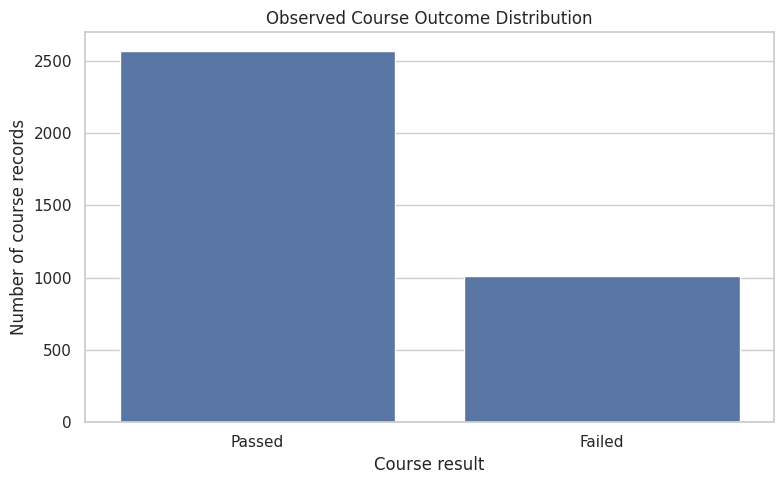

,period_index,period_label,enrolled,passed,failed,failure_rate,pass_rate
0,1,"1st Semester, AY 2022-2023",400,317,83,0.207500,0.792500
1,2,"2nd Semester, AY 2022-2023",483,357,126,0.260870,0.739130
2,3,"1st Semester, AY 2023-2024",834,592,242,0.290168,0.709832
3,4,"2nd Semester, AY 2023-2024",922,635,287,0.311280,0.688720
4,5,"1st Semester, AY 2024-2025",942,666,276,0.292994,0.707006


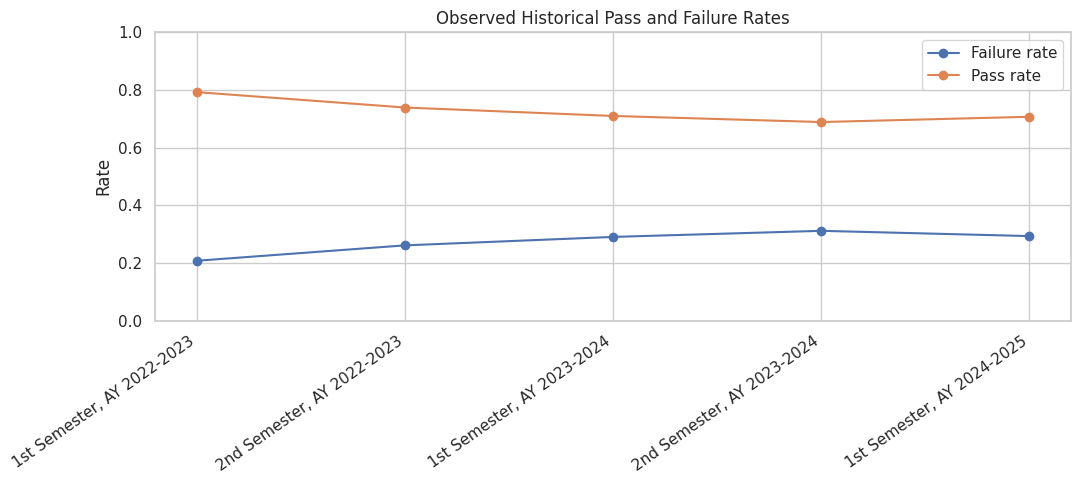

,program_code,attempts,passed,failed,repeated,failure_rate
0,BSBA,1291,896,395,278,0.305964
1,BSED,1003,776,227,170,0.226321
2,BSIT,1287,895,392,265,0.304584


In [ ]:
# Course-level aggregate from individual student-course records
course_outcomes = (
    sh.groupby("course_id")
      .agg(
          students_observed=("student_id", "nunique"),
          course_attempts=("history_id", "count"),
          passed_attempts=("is_passed", "sum"),
          failed_attempts=("is_failed", "sum"),
          withdrawn_attempts=("is_withdrawn", "sum"),
          repeated_attempts=("is_repeated", "sum"),
          average_grade=("final_grade", "mean")
      ).reset_index()
)
course_outcomes["attempts_with_known_outcome"] = (
    course_outcomes["passed_attempts"] + course_outcomes["failed_attempts"]
    + course_outcomes["withdrawn_attempts"]
)
course_outcomes["pass_rate"] = (
    course_outcomes["passed_attempts"] /
    course_outcomes["attempts_with_known_outcome"].replace(0, np.nan)
)
course_outcomes["failure_rate"] = (
    course_outcomes["failed_attempts"] /
    course_outcomes["attempts_with_known_outcome"].replace(0, np.nan)
)
course_outcomes["repeat_rate"] = (
    course_outcomes["repeated_attempts"] /
    course_outcomes["course_attempts"].replace(0, np.nan)
)

course_summary = cm.merge(course_outcomes, on="course_id", how="left")
course_summary = course_summary.sort_values(
    ["failure_rate", "failed_attempts"], ascending=[False, False]
)
display(course_summary.head(15))

# Overall outcome distribution
outcome_counts = sh["course_result_clean"].value_counts().rename_axis("result").reset_index(name="records")
display(outcome_counts)

plt.figure(figsize=(8, 5))
sns.barplot(data=outcome_counts, x="result", y="records")
plt.title("Observed Course Outcome Distribution")
plt.xlabel("Course result")
plt.ylabel("Number of course records")
plt.tight_layout()
plt.show()

# Historical course performance trend
historical_summary = (
    hc.groupby(["period_index", "period_label"], dropna=False)
      .agg(
          enrolled=("total_enrolled", "sum"),
          passed=("total_passed", "sum"),
          failed=("total_failed", "sum")
      ).reset_index().sort_values("period_index")
)
historical_summary["failure_rate"] = historical_summary["failed"] / historical_summary["enrolled"].replace(0, np.nan)
historical_summary["pass_rate"] = historical_summary["passed"] / historical_summary["enrolled"].replace(0, np.nan)
display(historical_summary)

plt.figure(figsize=(11, 5))
plt.plot(historical_summary["period_label"], historical_summary["failure_rate"], marker="o", label="Failure rate")
plt.plot(historical_summary["period_label"], historical_summary["pass_rate"], marker="o", label="Pass rate")
plt.xticks(rotation=35, ha="right")
plt.ylabel("Rate")
plt.ylim(0, 1)
plt.title("Observed Historical Pass and Failure Rates")
plt.legend()
plt.tight_layout()
plt.show()

# Program-level observed outcome summary
program_summary = (
    sh.merge(cm[["course_id", "program_code"]], on="course_id", how="left")
      .groupby("program_code")
      .agg(
          attempts=("history_id", "count"),
          passed=("is_passed", "sum"),
          failed=("is_failed", "sum"),
          repeated=("is_repeated", "sum")
      ).reset_index()
)
program_summary["failure_rate"] = program_summary["failed"] / (program_summary["passed"] + program_summary["failed"]).replace(0, np.nan)
display(program_summary)

## Task 4 — Apriori Association Rule Mining

Create student-period transactions containing courses recorded as failed in the same academic period. Apriori identifies recurring co-failure combinations. Support, confidence, and lift describe association strength only; they do not establish that one course failure causes another.

In [ ]:
# Each transaction = one student in one academic period, containing their failed courses.
failed_rows = sh[sh["is_failed"] & sh["period_index"].notna()].copy()
failed_transactions = (
    failed_rows.groupby(["student_id", "period_index"])["course_id"]
               .apply(lambda x: sorted(set(x.astype(str))))
               .tolist()
)
failed_transactions = [t for t in failed_transactions if len(t) >= 1]

print("Student-period failed-course transactions:", len(failed_transactions))
print("Transactions with 2+ failed courses:", sum(len(t) >= 2 for t in failed_transactions))

MIN_SUPPORT = 0.02
MIN_CONFIDENCE = 0.40

if failed_transactions:
    encoder = TransactionEncoder()
    encoded_array = encoder.fit(failed_transactions).transform(failed_transactions)
    failed_encoded = pd.DataFrame(encoded_array, columns=encoder.columns_)

    frequent_itemsets = apriori(
        failed_encoded, min_support=MIN_SUPPORT, use_colnames=True, max_len=4
    )
    if not frequent_itemsets.empty:
        frequent_itemsets["itemset_length"] = frequent_itemsets["itemsets"].apply(len)
        failed_rules = association_rules(
            frequent_itemsets, metric="confidence", min_threshold=MIN_CONFIDENCE
        )
        failed_rules = failed_rules.sort_values(
            ["lift", "confidence", "support"], ascending=False
        )
    else:
        failed_rules = pd.DataFrame()
else:
    frequent_itemsets = pd.DataFrame()
    failed_rules = pd.DataFrame()

if not frequent_itemsets.empty:
    itemset_display = frequent_itemsets.copy()
    itemset_display["course_ids"] = itemset_display["itemsets"].apply(lambda x: ", ".join(sorted(x)))
    display(itemset_display.sort_values(["itemset_length", "support"], ascending=[False, False]).head(20))
else:
    print("No frequent itemsets at the selected support threshold. Consider a lower threshold and document the choice.")

if not failed_rules.empty:
    rule_display = failed_rules.copy()
    rule_display["antecedent_courses"] = rule_display["antecedents"].apply(lambda x: ", ".join(sorted(x)))
    rule_display["consequent_courses"] = rule_display["consequents"].apply(lambda x: ", ".join(sorted(x)))
    display(rule_display[["antecedent_courses", "consequent_courses", "support", "confidence", "lift"]].head(20))
else:
    print("No association rules met the selected confidence threshold.")

# Map IDs to course codes for readable interpretation
course_code_lookup = dict(zip(cm["course_id"].astype(str), cm["course_code"].astype(str)))
if not frequent_itemsets.empty:
    frequent_itemsets["course_codes"] = frequent_itemsets["itemsets"].apply(
        lambda x: ", ".join(course_code_lookup.get(str(cid), str(cid)) for cid in sorted(x))
    )
if not failed_rules.empty:
    failed_rules["antecedent_codes"] = failed_rules["antecedents"].apply(
        lambda x: ", ".join(course_code_lookup.get(str(cid), str(cid)) for cid in sorted(x))
    )
    failed_rules["consequent_codes"] = failed_rules["consequents"].apply(
        lambda x: ", ".join(course_code_lookup.get(str(cid), str(cid)) for cid in sorted(x))
    )

Student-period failed-course transactions: 633
Transactions with 2+ failed courses: 275


,support,itemsets,itemset_length,course_ids
32,0.047393,"(C016, C018)",2,"C016, C018"
27,0.042654,"(C005, C006)",2,"C005, C006"
30,0.039494,"(C014, C016)",2,"C014, C016"
31,0.031596,"(C014, C018)",2,"C014, C018"
24,0.028436,"(C002, C006)",2,"C002, C006"
28,0.026856,"(C005, C007)",2,"C005, C007"
34,0.026856,"(C017, C018)",2,"C017, C018"
23,0.025276,"(C005, C002)",2,"C002, C005"
25,0.025276,"(C005, C004)",2,"C004, C005"
29,0.022117,"(C013, C018)",2,"C013, C018"


,antecedent_courses,consequent_courses,support,confidence,lift
3,C017,C018,0.026856,0.586207,4.216693
0,C006,C005,0.042654,0.442623,3.592055
1,C007,C005,0.026856,0.425000,3.449038
2,C019,C016,0.022117,0.482759,3.285873
4,C019,C018,0.020537,0.448276,3.224530


## Task 5 — Diagnostic Analysis of Course Bottlenecks and Prerequisite Relationships

Examine prerequisite-to-successor links, observed failures in prerequisite courses, and subsequent student attempts in successor courses. The analysis distinguishes curriculum relationships from directly observed student histories and avoids causal claims.

,prerequisite_course_id,succeeding_course_id,students_with_prerequisite_failure,students_with_successor_attempt,students_with_successor_pass,prerequisite_code,prerequisite_name,successor_code,successor_name
16,C018,C020,50,58,42,BA202,Cost Accounting,BA204,Financial Management
14,C016,C020,49,55,43,BA104,Financial Accounting,BA204,Financial Management
13,C016,C018,49,82,42,BA104,Financial Accounting,BA202,Cost Accounting
5,C005,C007,48,60,37,IT201,Data Structures and Algorithms,IT203,Object-Oriented Programming
4,C005,C006,48,71,42,IT201,Data Structures and Algorithms,IT202,Database Management Systems
11,C014,C019,46,58,41,BA102,Business Mathematics,BA203,Business Statistics
10,C014,C016,46,79,43,BA102,Business Mathematics,BA104,Financial Accounting
1,C002,C004,41,61,41,IT102,Computer Programming 1,IT104,Computer Programming 2
22,C028,C030,41,52,36,ED104,Assessment of Learning 1,ED202,Assessment of Learning 2
6,C006,C009,39,0,0,IT202,Database Management Systems,IT301,Systems Analysis and Design


,course_id,course_code,course_name,direct_successors,direct_prerequisites
4,C005,IT201,Data Structures and Algorithms,2,2
13,C014,BA102,Business Mathematics,2,0
24,C025,ED101,Foundations of Education,2,0
26,C027,ED103,Facilitating Learner-Centered Teaching,2,1
15,C016,BA104,Financial Accounting,2,1
1,C002,IT102,Computer Programming 1,1,1
5,C006,IT202,Database Management Systems,1,1
6,C007,IT203,Object-Oriented Programming,1,1
8,C009,IT301,Systems Analysis and Design,1,1
7,C008,IT204,Networking Fundamentals,1,0


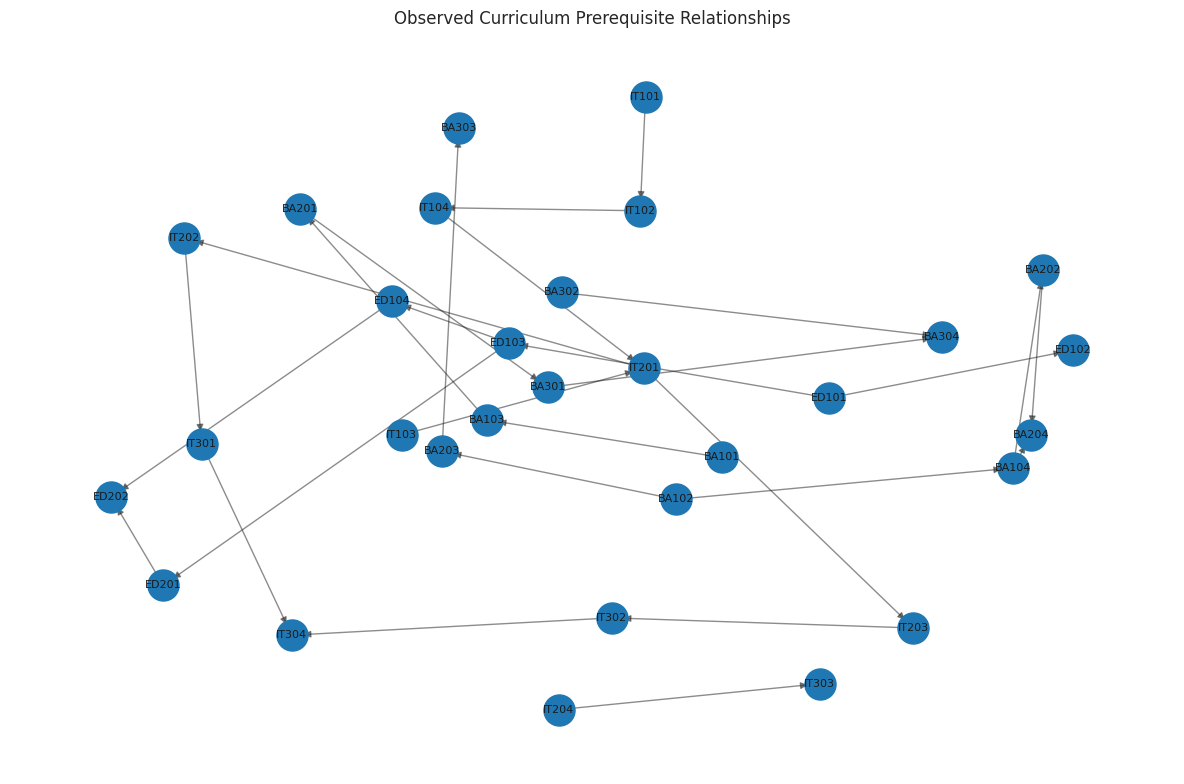

In [ ]:
# Retain active prerequisite relationships; exclude explicit corequisites from prerequisite bottleneck counts.
pm_diag = pm.copy()
pm_diag["relationship_status_norm"] = pm_diag["relationship_status"].astype(str).str.strip().str.lower()
pm_diag["dependency_type_norm"] = pm_diag["dependency_type"].astype(str).str.strip().str.lower()
active_terms = {"active", "current", "approved", "valid"}
pm_diag = pm_diag[
    pm_diag["relationship_status_norm"].isin(active_terms)
    | pm_diag["relationship_status_norm"].eq("nan")
].copy()
pm_diag = pm_diag[~pm_diag["dependency_type_norm"].str.contains("co.?req", na=False)]

# Curriculum graph and direct-successor counts
G = nx.DiGraph()
G.add_nodes_from(cm["course_id"].astype(str))
for r in pm_diag.itertuples():
    pre, suc = str(r.prerequisite_course_id), str(r.succeeding_course_id)
    if pre in G and suc in G and pre != suc:
        G.add_edge(pre, suc)

successor_counts = pd.DataFrame({
    "course_id": list(G.nodes),
    "direct_successors": [G.out_degree(n) for n in G.nodes],
    "direct_prerequisites": [G.in_degree(n) for n in G.nodes]
})

# Observed student-level evidence:
# A student is counted as having a failed prerequisite when the student has a failed
# record for the prerequisite course. A successor attempt is counted separately.
student_course_flags = (
    sh.groupby(["student_id", "course_id"])
      .agg(
          ever_failed=("is_failed", "max"),
          ever_passed=("is_passed", "max"),
          attempts=("history_id", "count")
      ).reset_index()
)
failed_prereq_pairs = student_course_flags[
    student_course_flags["ever_failed"]
][["student_id", "course_id"]].rename(columns={"course_id": "prerequisite_course_id"})

if not pm_diag.empty and not failed_prereq_pairs.empty:
    prereq_student = failed_prereq_pairs.merge(
        pm_diag[["prerequisite_course_id", "succeeding_course_id"]],
        on="prerequisite_course_id", how="inner"
    )
    successor_attempts = sh[["student_id", "course_id", "course_result_clean"]].drop_duplicates()
    prereq_student = prereq_student.merge(
        successor_attempts,
        left_on=["student_id", "succeeding_course_id"],
        right_on=["student_id", "course_id"],
        how="left",
        indicator=True
    )
    prereq_student["successor_attempt_observed"] = prereq_student["_merge"].eq("both")
    prereq_student["successor_pass_observed"] = (
        prereq_student["successor_attempt_observed"]
        & prereq_student["course_result_clean"].eq("Passed")
    )
    prereq_diagnostic = (
        prereq_student.groupby(["prerequisite_course_id", "succeeding_course_id"])
        .agg(
            students_with_prerequisite_failure=("student_id", "nunique"),
            students_with_successor_attempt=("successor_attempt_observed", "sum"),
            students_with_successor_pass=("successor_pass_observed", "sum")
        ).reset_index()
    )
else:
    prereq_diagnostic = pd.DataFrame(columns=[
        "prerequisite_course_id", "succeeding_course_id",
        "students_with_prerequisite_failure", "students_with_successor_attempt",
        "students_with_successor_pass"
    ])

prereq_diagnostic = (
    prereq_diagnostic
    .merge(cm[["course_id", "course_code", "course_name"]],
           left_on="prerequisite_course_id", right_on="course_id", how="left")
    .rename(columns={"course_code": "prerequisite_code", "course_name": "prerequisite_name"})
    .drop(columns=["course_id"])
    .merge(cm[["course_id", "course_code", "course_name"]],
           left_on="succeeding_course_id", right_on="course_id", how="left")
    .rename(columns={"course_code": "successor_code", "course_name": "successor_name"})
    .drop(columns=["course_id"])
)
display(prereq_diagnostic.sort_values("students_with_prerequisite_failure", ascending=False).head(25))

# Summarize prerequisite structure per course
prerequisite_structure = (
    cm[["course_id", "course_code", "course_name"]]
    .merge(successor_counts, on="course_id", how="left")
    .fillna({"direct_successors": 0, "direct_prerequisites": 0})
)
display(prerequisite_structure.sort_values("direct_successors", ascending=False).head(15))

# Visualize the curriculum prerequisite network
if G.number_of_edges() > 0:
    plt.figure(figsize=(12, 8))
    pos = nx.spring_layout(G, seed=RANDOM_STATE, k=0.8)
    nx.draw_networkx_nodes(G, pos, node_size=500)
    nx.draw_networkx_edges(G, pos, arrows=True, alpha=0.5)
    labels = {r.course_id: r.course_code for r in cm.itertuples() if r.course_id in G}
    nx.draw_networkx_labels(G, pos, labels=labels, font_size=8)
    plt.title("Observed Curriculum Prerequisite Relationships")
    plt.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("No active prerequisite edges were available for network visualization.")

## Task 6 — Academic Progression and Historical Trend Analysis

Summarize actual recorded student-course histories by academic period. Report observed cumulative attempts, passes, failures, repeats, and completion proportions. These are historical summaries, not future-state estimates.

,period_index,period_label,students_observed,courses_attempted,courses_passed,courses_failed,courses_repeated,mean_student_completion_rate,observed_pass_rate
0,1,"1st Semester, AY 2022-2023",200,400,317,83,0,0.792500,0.792500
1,2,"2nd Semester, AY 2022-2023",200,483,357,126,83,0.740833,0.739130
2,3,"1st Semester, AY 2023-2024",200,834,592,242,126,0.718500,0.709832
3,4,"2nd Semester, AY 2023-2024",200,922,635,287,231,0.697333,0.688720
4,5,"1st Semester, AY 2024-2025",200,942,666,276,273,0.717750,0.707006


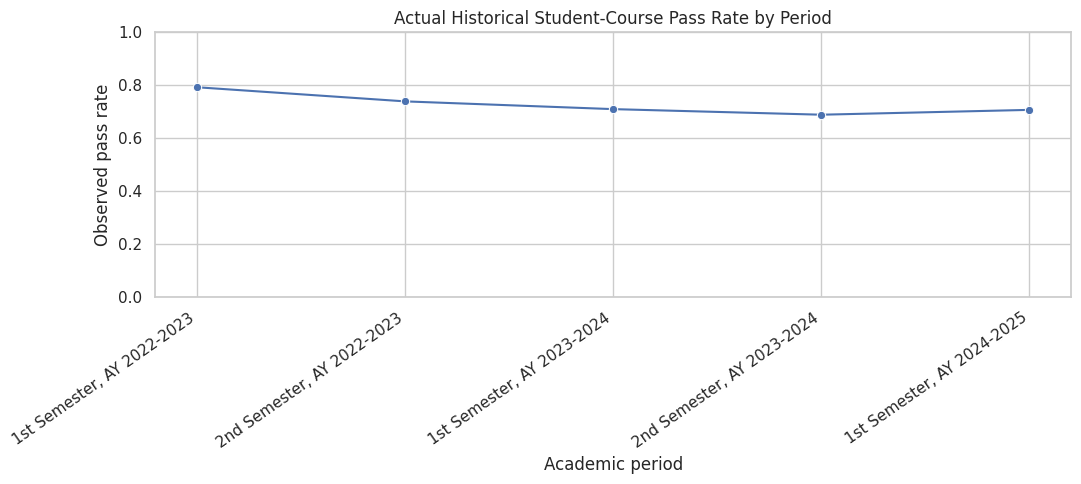

,student_id,program_code,college_code,admission_year,last_observed_semester,last_observed_academic_year,total_courses_taken,total_courses_passed,total_courses_failed,total_courses_repeated,actual_completion_rate,failed_course_ids,prerequisite_successor_courses_of_failed_courses,historical_status,reconstructed_courses_taken,reconstructed_courses_passed,reconstructed_courses_failed,reconstructed_courses_repeated,taken_difference,passed_difference
0,S0001,BSIT,CICS,2022,1st Semester,2024-2025,20,12,8,6,60.00,C002;C004;C005;C007,C004;C005;C006;C007;C010,Has recorded failures,20,12,8,6,0,0
1,S0002,BSBA,CBA,2022,1st Semester,2024-2025,18,15,3,2,83.33,C018;C020,C020,Has recorded failures,18,15,3,2,0,0
2,S0003,BSED,CTE,2022,1st Semester,2024-2025,15,13,2,2,86.67,C025;C027,C026;C027;C028;C029,Has recorded failures,15,13,2,2,0,0
3,S0004,BSIT,CICS,2022,1st Semester,2024-2025,18,12,6,2,66.67,C002;C005;C006;C007,C004;C006;C007;C009;C010,Has recorded failures,18,12,6,2,0,0
4,S0005,BSBA,CBA,2022,1st Semester,2024-2025,17,15,2,1,88.24,C014;C016,C016;C018;C019;C020,Has recorded failures,17,15,2,1,0,0
5,S0006,BSED,CTE,2022,1st Semester,2024-2025,14,12,2,1,85.71,C030,NaN,Has recorded failures,14,12,2,1,0,0
6,S0007,BSIT,CICS,2022,1st Semester,2024-2025,19,15,4,3,78.95,C002;C006,C004;C009,Has recorded failures,19,15,4,3,0,0
7,S0008,BSBA,CBA,2022,1st Semester,2024-2025,21,12,9,8,57.14,C013;C014;C016;C018,C015;C016;C018;C019;C020,Has recorded failures,21,12,9,8,0,0
8,S0009,BSED,CTE,2022,1st Semester,2024-2025,13,13,0,0,100.00,NaN,NaN,No recorded failures,13,13,0,0,0,0
9,S0010,BSIT,CICS,2022,1st Semester,2024-2025,22,12,10,8,54.55,C001;C002;C003;C004;C006;C008,C002;C004;C005;C009;C011,Has recorded failures,22,12,10,8,0,0


,historical_status,students
0,Has recorded failures,196
1,No recorded failures,4


In [ ]:
# Actual student-period outcomes
student_period = (
    sh.groupby(["student_id", "period_index", "period_label"], dropna=False)
      .agg(
          courses_attempted=("history_id", "count"),
          courses_passed=("is_passed", "sum"),
          courses_failed=("is_failed", "sum"),
          courses_repeated=("is_repeated", "sum")
      ).reset_index()
      .sort_values(["student_id", "period_index"])
)
student_period["period_completion_rate"] = (
    student_period["courses_passed"] /
    student_period["courses_attempted"].replace(0, np.nan)
)
student_period["cumulative_courses_attempted"] = (
    student_period.groupby("student_id")["courses_attempted"].cumsum()
)
student_period["cumulative_courses_passed"] = (
    student_period.groupby("student_id")["courses_passed"].cumsum()
)
student_period["cumulative_courses_failed"] = (
    student_period.groupby("student_id")["courses_failed"].cumsum()
)
student_period["actual_cumulative_completion_rate"] = (
    student_period["cumulative_courses_passed"] /
    student_period["cumulative_courses_attempted"].replace(0, np.nan)
)

period_progression = (
    student_period.groupby(["period_index", "period_label"])
    .agg(
        students_observed=("student_id", "nunique"),
        courses_attempted=("courses_attempted", "sum"),
        courses_passed=("courses_passed", "sum"),
        courses_failed=("courses_failed", "sum"),
        courses_repeated=("courses_repeated", "sum"),
        mean_student_completion_rate=("period_completion_rate", "mean")
    ).reset_index().sort_values("period_index")
)
period_progression["observed_pass_rate"] = (
    period_progression["courses_passed"] /
    (period_progression["courses_passed"] + period_progression["courses_failed"]).replace(0, np.nan)
)
display(period_progression)

plt.figure(figsize=(11, 5))
sns.lineplot(data=period_progression, x="period_label", y="observed_pass_rate", marker="o")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 1)
plt.title("Actual Historical Student-Course Pass Rate by Period")
plt.xlabel("Academic period")
plt.ylabel("Observed pass rate")
plt.tight_layout()
plt.show()

# Compare provided progression summary with independently reconstructed history.
reconstructed_student = (
    sh.groupby("student_id")
      .agg(
          reconstructed_courses_taken=("history_id", "count"),
          reconstructed_courses_passed=("is_passed", "sum"),
          reconstructed_courses_failed=("is_failed", "sum"),
          reconstructed_courses_repeated=("is_repeated", "sum")
      ).reset_index()
)
progression_comparison = sp.merge(reconstructed_student, on="student_id", how="left")
progression_comparison["taken_difference"] = (
    progression_comparison["total_courses_taken"] - progression_comparison["reconstructed_courses_taken"]
)
progression_comparison["passed_difference"] = (
    progression_comparison["total_courses_passed"] - progression_comparison["reconstructed_courses_passed"]
)
display(progression_comparison.head(15))

# Distribution of the dataset's supplied historical status labels (not a predicted status).
if "historical_status" in sp.columns:
    display(sp["historical_status"].value_counts(dropna=False).rename_axis("historical_status").reset_index(name="students"))

## Task 7 — Course Bottleneck Ranking and Management Recommendations

Rank courses using observed evidence only. The composite score combines observed failure rate, repeat rate, recurrence across periods, student impact, and curriculum downstream reach. Component weights are explicit and sum to 1.0. The score is a prioritization aid, not a prediction of future failure.

,rank,course_code,course_name,program_code,historical_failure_rate,observed_repeat_rate,historical_periods,students_with_observed_failure,direct_successors,bottleneck_score,priority,management_recommendation
0,1,BA104,Financial Accounting,BSBA,0.474490,0.392857,4.0,49.0,2,90.833333,High priority,Review assessment results and provide targeted...
1,2,BA202,Cost Accounting,BSBA,0.523810,0.315476,3.0,50.0,1,84.833333,High priority,Review assessment results and provide targeted...
2,3,IT201,Data Structures and Algorithms,BSIT,0.490566,0.238994,3.0,48.0,2,83.833333,High priority,Review assessment results and provide targeted...
3,4,ED104,Assessment of Learning 1,BSED,0.429348,0.375000,4.0,41.0,1,82.250000,Moderate priority,Review assessment results and provide targeted...
4,5,BA102,Business Mathematics,BSBA,0.309623,0.225941,5.0,46.0,2,80.333333,Moderate priority,Review assessment results and provide targeted...
5,6,IT104,Computer Programming 2,BSIT,0.331461,0.286517,4.0,36.0,1,75.916667,Moderate priority,Review assessment results and provide targeted...
6,7,IT102,Computer Programming 1,BSIT,0.288066,0.222222,5.0,41.0,1,73.916667,Moderate priority,Review assessment results and provide targeted...
7,8,IT203,Object-Oriented Programming,BSIT,0.430108,0.279570,2.0,27.0,1,71.166667,Moderate priority,Review assessment results and provide targeted...
8,9,IT202,Database Management Systems,BSIT,0.393548,0.193548,3.0,39.0,1,70.666667,Routine monitoring,Review assessment results and provide targeted...
9,10,IT101,Introduction to Computing,BSIT,0.216450,0.160173,5.0,36.0,1,67.416667,Routine monitoring,Review assessment results and provide targeted...


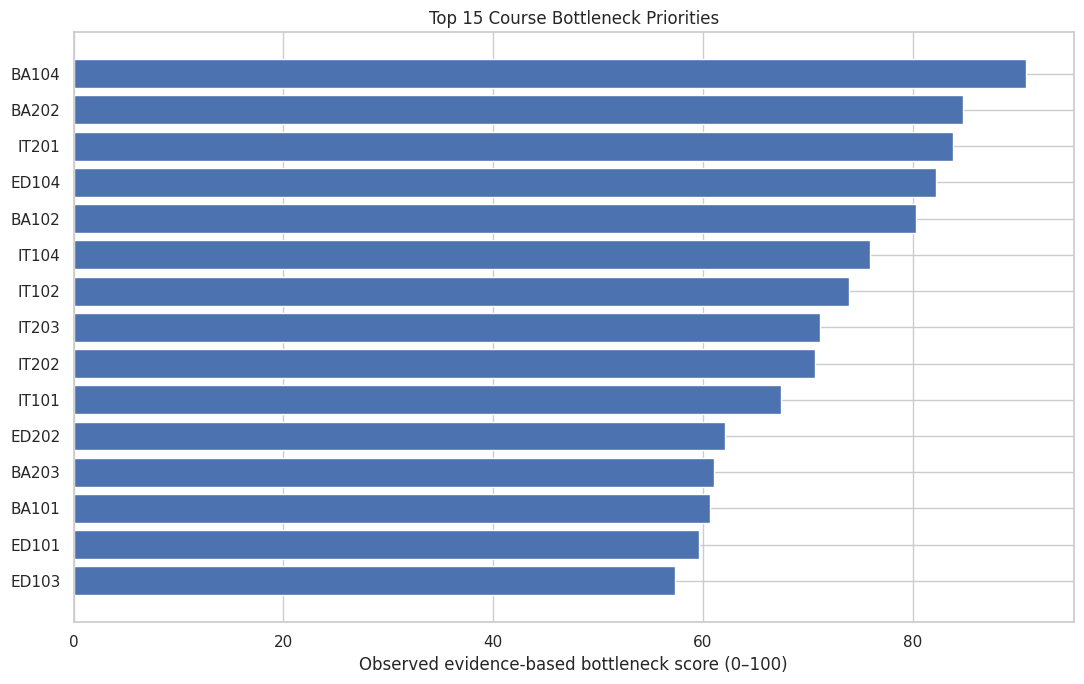

Ranking weights:


,component,weight
0,failure_component,0.35
1,repeat_component,0.20
2,recurrence_component,0.20
3,student_impact_component,0.15
4,downstream_component,0.10


In [ ]:
# Build observed course-period panel from historical records and individual histories.
panel_hist = hc.groupby("course_id").agg(
    historical_periods=("period_index", "nunique"),
    historical_enrolled=("total_enrolled", "sum"),
    historical_failed=("total_failed", "sum"),
    historical_passed=("total_passed", "sum"),
    historical_withdrawn=("total_withdrawn", "sum")
).reset_index()
panel_hist["historical_failure_rate"] = (
    panel_hist["historical_failed"] /
    (panel_hist["historical_failed"] + panel_hist["historical_passed"]).replace(0, np.nan)
)

observed_student_impact = (
    sh[sh["is_failed"]].groupby("course_id")["student_id"].nunique()
    .rename("students_with_observed_failure").reset_index()
)
repeat_summary = (
    sh.groupby("course_id")
      .agg(total_attempts=("history_id", "count"),
           repeated_attempts=("is_repeated", "sum"))
      .reset_index()
)
repeat_summary["observed_repeat_rate"] = (
    repeat_summary["repeated_attempts"] / repeat_summary["total_attempts"].replace(0, np.nan)
)

ranking = (
    cm[["course_id", "course_code", "course_name", "program_code", "year_level"]]
    .merge(panel_hist, on="course_id", how="left")
    .merge(observed_student_impact, on="course_id", how="left")
    .merge(repeat_summary, on="course_id", how="left")
    .merge(successor_counts, on="course_id", how="left")
)
numeric_zero = [
    "historical_periods", "historical_enrolled", "historical_failed",
    "historical_passed", "historical_withdrawn",
    "students_with_observed_failure", "total_attempts", "repeated_attempts",
    "direct_successors", "direct_prerequisites"
]
for col in numeric_zero:
    ranking[col] = ranking[col].fillna(0)
ranking["historical_failure_rate"] = ranking["historical_failure_rate"].fillna(0)
ranking["observed_repeat_rate"] = ranking["observed_repeat_rate"].fillna(0)

def percentile_component(series):
    if series.nunique(dropna=True) <= 1:
        return pd.Series(0.0, index=series.index)
    return series.rank(pct=True, method="average").fillna(0)

ranking["failure_component"] = percentile_component(ranking["historical_failure_rate"])
ranking["repeat_component"] = percentile_component(ranking["observed_repeat_rate"])
ranking["recurrence_component"] = percentile_component(ranking["historical_periods"])
ranking["student_impact_component"] = percentile_component(ranking["students_with_observed_failure"])
ranking["downstream_component"] = percentile_component(ranking["direct_successors"])

WEIGHTS = {
    "failure_component": 0.35,
    "repeat_component": 0.20,
    "recurrence_component": 0.20,
    "student_impact_component": 0.15,
    "downstream_component": 0.10
}
assert np.isclose(sum(WEIGHTS.values()), 1.0)

ranking["bottleneck_score"] = sum(
    ranking[col] * weight for col, weight in WEIGHTS.items()
) * 100

# Transparent descriptive priority bands based on score distribution.
q75 = ranking["bottleneck_score"].quantile(0.75)
q90 = ranking["bottleneck_score"].quantile(0.90)
def priority_band(score):
    if score >= q90 and score > 0:
        return "High priority"
    if score >= q75 and score > 0:
        return "Moderate priority"
    return "Routine monitoring"

ranking["priority"] = ranking["bottleneck_score"].map(priority_band)
ranking = ranking.sort_values(
    ["bottleneck_score", "historical_failure_rate", "students_with_observed_failure"],
    ascending=False
).reset_index(drop=True)
ranking.insert(0, "rank", np.arange(1, len(ranking) + 1))

def recommendation(row):
    actions = []
    if row["historical_failure_rate"] > 0:
        actions.append("Review assessment results and provide targeted course support")
    if row["observed_repeat_rate"] > 0:
        actions.append("Review repeat-attempt patterns and offer academic advising")
    if row["historical_periods"] >= 2:
        actions.append("Monitor performance across successive observed periods")
    if row["direct_successors"] > 0:
        actions.append("Review prerequisite readiness and support for successor courses")
    if row["students_with_observed_failure"] > 0:
        actions.append("Prioritize students with recorded unsuccessful attempts")
    return "; ".join(dict.fromkeys(actions)) if actions else "Continue routine monitoring"

ranking["management_recommendation"] = ranking.apply(recommendation, axis=1)

display(ranking[[
    "rank", "course_code", "course_name", "program_code",
    "historical_failure_rate", "observed_repeat_rate",
    "historical_periods", "students_with_observed_failure",
    "direct_successors", "bottleneck_score", "priority",
    "management_recommendation"
]].head(20))

top_ranked = ranking.head(15).sort_values("bottleneck_score")
plt.figure(figsize=(11, 7))
plt.barh(top_ranked["course_code"], top_ranked["bottleneck_score"])
plt.xlabel("Observed evidence-based bottleneck score (0–100)")
plt.title("Top 15 Course Bottleneck Priorities")
plt.tight_layout()
plt.show()

print("Ranking weights:")
display(pd.DataFrame({"component": list(WEIGHTS), "weight": list(WEIGHTS.values())}))

## Task 8 — Results Validation and Dashboard Export

Run data-integrity and analysis checks, export the descriptive and diagnostic tables, and package CSV outputs and figures. No model accuracy score is calculated because this workflow does not train a predictive model.

In [ ]:
# Validation checks for source data and derived analysis
checks = []

def add_check(name, condition, detail=""):
    checks.append({
        "check": name,
        "passed": bool(condition),
        "detail": str(detail)
    })

add_check("Course master course_id is unique", cm["course_id"].is_unique)
add_check("Student-course history has no missing student_id", sh["student_id"].notna().all())
add_check("Student-course history has no missing course_id", sh["course_id"].notna().all())
add_check("History course IDs exist in course master",
          set(sh["course_id"].dropna().astype(str)).issubset(set(cm["course_id"].astype(str))))
add_check("Prerequisite course IDs exist in course master",
          set(pm["prerequisite_course_id"].dropna().astype(str)).issubset(set(cm["course_id"].astype(str))))
add_check("Succeeding course IDs exist in course master",
          set(pm["succeeding_course_id"].dropna().astype(str)).issubset(set(cm["course_id"].astype(str))))
add_check("Historical period indices parsed",
          hc["period_index"].notna().all())
add_check("Observed pass/failure rates are within 0–1",
          course_outcomes[["pass_rate", "failure_rate"]].dropna().apply(
              lambda col: col.between(0, 1).all()
          ).all())
add_check("Ranking contains every course exactly once",
          ranking["course_id"].is_unique and set(ranking["course_id"]) == set(cm["course_id"]))
add_check("Ranking weights sum to 1", np.isclose(sum(WEIGHTS.values()), 1.0))
add_check("Bottleneck scores are within 0–100",
          ranking["bottleneck_score"].between(0, 100).all())

validation_report = pd.DataFrame(checks)
display(validation_report)
print(f"Passed {validation_report['passed'].sum()} of {len(validation_report)} validation checks.")

,check,passed,detail
0,Course master course_id is unique,True,
1,Student-course history has no missing student_id,True,
2,Student-course history has no missing course_id,True,
3,History course IDs exist in course master,True,
4,Prerequisite course IDs exist in course master,True,
5,Succeeding course IDs exist in course master,True,
6,Historical period indices parsed,True,
7,Observed pass/failure rates are within 0–1,True,
8,Ranking contains every course exactly once,True,
9,Ranking weights sum to 1,True,


Passed 11 of 11 validation checks.


In [ ]:

# ============================================================
# ANALYTICAL AND SYSTEM PERFORMANCE EVALUATION
# Course Bottleneck Detection and Academic Progression Analysis
# Descriptive and Diagnostic Analytics
# ============================================================

import pandas as pd
import numpy as np
import time
from pathlib import Path

evaluation_start = time.perf_counter()

evaluation_results = []
evaluation_details = {}

def add_result(category, metric, value, status, remarks=""):
    evaluation_results.append({
        "evaluation_category": category,
        "metric": metric,
        "result": value,
        "status": status,
        "remarks": remarks
    })

def safe_percentage(numerator, denominator):
    if denominator == 0:
        return np.nan
    return round((numerator / denominator) * 100, 2)


# ============================================================
# 1. DATA QUALITY AND COMPLETENESS
# ============================================================

print("=" * 65)
print("1. DATA QUALITY AND COMPLETENESS EVALUATION")
print("=" * 65)

for name, df in datasets.items():

    total_cells = df.size
    missing_cells = int(df.isna().sum().sum())
    duplicate_rows = int(df.duplicated().sum())

    completeness = safe_percentage(
        total_cells - missing_cells,
        total_cells
    )

    duplicate_rate = safe_percentage(
        duplicate_rows,
        len(df)
    )

    add_result(
        "Data Quality",
        f"{name} - Completeness",
        completeness,
        "PASS" if completeness == 100 else "REVIEW",
        f"{missing_cells} missing cells out of {total_cells}"
    )

    add_result(
        "Data Quality",
        f"{name} - Duplicate Rate",
        duplicate_rate,
        "PASS" if duplicate_rows == 0 else "REVIEW",
        f"{duplicate_rows} duplicate rows out of {len(df)}"
    )

    evaluation_details[name] = {
        "rows": len(df),
        "columns": len(df.columns),
        "missing_cells": missing_cells,
        "duplicate_rows": duplicate_rows,
        "completeness_percent": completeness,
        "duplicate_rate_percent": duplicate_rate
    }


# ============================================================
# 2. COURSE PERFORMANCE CALCULATION VALIDATION
# ============================================================

print("\n" + "=" * 65)
print("2. COURSE PERFORMANCE CALCULATION VALIDATION")
print("=" * 65)

performance_dfs = {
    "course_performance": cp,
    "historical_course_records": hc
}

for dataset_name, df in performance_dfs.items():

    required = {
        "total_enrolled",
        "total_passed",
        "total_failed"
    }

    if required.issubset(df.columns):

        temp = df.copy()

        enrolled = pd.to_numeric(
            temp["total_enrolled"], errors="coerce"
        )

        passed = pd.to_numeric(
            temp["total_passed"], errors="coerce"
        )

        failed = pd.to_numeric(
            temp["total_failed"], errors="coerce"
        )

        valid = (
            enrolled.notna()
            & passed.notna()
            & failed.notna()
            & enrolled.gt(0)
        )

        temp = temp.loc[valid].copy()

        enrolled = enrolled.loc[valid]
        passed = passed.loc[valid]
        failed = failed.loc[valid]

        # Recalculate rates from observed counts
        calculated_failure = failed / enrolled
        calculated_pass = passed / enrolled

        invalid_counts = (
            passed.lt(0)
            | failed.lt(0)
            | passed.gt(enrolled)
            | failed.gt(enrolled)
            | (passed + failed).gt(enrolled)
        )

        add_result(
            "Analytical Accuracy",
            f"{dataset_name} - Valid Enrollment Counts",
            int((~invalid_counts).sum()),
            "PASS" if not invalid_counts.any() else "REVIEW",
            f"{int(invalid_counts.sum())} records have invalid counts"
        )

        # Compare against source rates if available
        if "failure_rate" in temp.columns:

            source_rate = pd.to_numeric(
                temp["failure_rate"], errors="coerce"
            )

            # Handle percentages stored as 0-100
            if source_rate.dropna().gt(1).any():
                source_rate = source_rate / 100

            comparable = source_rate.notna()

            if comparable.any():

                differences = (
                    calculated_failure[comparable]
                    - source_rate[comparable]
                ).abs()

                agreement = safe_percentage(
                    int((differences <= 0.0001).sum()),
                    len(differences)
                )

                add_result(
                    "Analytical Accuracy",
                    f"{dataset_name} - Failure Rate Agreement",
                    agreement,
                    "PASS" if agreement == 100 else "REVIEW",
                    "Comparison of recalculated and source failure rates"
                )

        evaluation_details[f"{dataset_name}_calculated_rates"] = {
            "valid_records": len(temp),
            "mean_failure_rate": (
                round(calculated_failure.mean() * 100, 2)
                if len(temp) else None
            ),
            "mean_pass_rate": (
                round(calculated_pass.mean() * 100, 2)
                if len(temp) else None
            )
        }

    else:
        add_result(
            "Analytical Accuracy",
            f"{dataset_name} - Course Rate Validation",
            "N/A",
            "NOT EVALUATED",
            "Required enrollment and outcome columns are unavailable"
        )


# ============================================================
# 3. HISTORICAL DATA CONSISTENCY
# ============================================================

print("\n" + "=" * 65)
print("3. HISTORICAL DATA CONSISTENCY")
print("=" * 65)

if {"course_id", "semester", "academic_year"}.issubset(hc.columns):

    period_duplicates = hc.duplicated(
        subset=["course_id", "semester", "academic_year"]
    ).sum()

    add_result(
        "Historical Consistency",
        "Duplicate Course-Academic Period Records",
        int(period_duplicates),
        "PASS" if period_duplicates == 0 else "REVIEW",
        "Checks whether a course has multiple records in the same period"
    )

else:
    add_result(
        "Historical Consistency",
        "Course-Academic Period Uniqueness",
        "N/A",
        "NOT EVALUATED",
        "Required columns are unavailable"
    )


# ============================================================
# 4. APRIORI ASSOCIATION RULE VALIDATION
# ============================================================

print("\n" + "=" * 65)
print("4. APRIORI ASSOCIATION RULE VALIDATION")
print("=" * 65)

if not frequent_itemsets.empty:

    required_itemset_cols = {"support", "itemsets"}

    if required_itemset_cols.issubset(frequent_itemsets.columns):

        support_values = pd.to_numeric(
            frequent_itemsets["support"], errors="coerce"
        )

        valid_support = (
            support_values.dropna().between(0, 1)
        )

        add_result(
            "Apriori Validation",
            "Valid Support Values",
            safe_percentage(
                int(valid_support.sum()),
                len(support_values.dropna())
            ),
            "PASS" if valid_support.all() else "REVIEW",
            "Support values must be between 0 and 1"
        )

        add_result(
            "Apriori Validation",
            "Frequent Itemsets Identified",
            len(frequent_itemsets),
            "PASS" if len(frequent_itemsets) > 0 else "REVIEW",
            "Number of observed frequent failed-course combinations"
        )

else:
    add_result(
        "Apriori Validation",
        "Frequent Itemsets Identified",
        0,
        "REVIEW",
        "No frequent itemsets were generated"
    )


if not failed_rules.empty:

    metric_checks = {
        "support": (0, 1),
        "confidence": (0, 1),
        "lift": (0, None)
    }

    for metric, bounds in metric_checks.items():

        if metric in failed_rules.columns:

            values = pd.to_numeric(
                failed_rules[metric], errors="coerce"
            ).dropna()

            if bounds[1] is None:
                valid = values.ge(bounds[0])
            else:
                valid = values.between(
                    bounds[0], bounds[1]
                )

            add_result(
                "Apriori Validation",
                f"Valid {metric.title()} Values",
                safe_percentage(int(valid.sum()), len(values)),
                "PASS" if valid.all() else "REVIEW",
                f"Valid {int(valid.sum())} out of {len(values)} rules"
            )

    add_result(
        "Apriori Validation",
        "Association Rules Generated",
        len(failed_rules),
        "PASS",
        "Rules describe associations, not causal relationships"
    )

else:
    add_result(
        "Apriori Validation",
        "Association Rules Generated",
        0,
        "REVIEW",
        "No association rules were generated"
    )


# ============================================================
# 5. BOTTLENECK RANKING VALIDATION
# ============================================================

print("\n" + "=" * 65)
print("5. BOTTLENECK RANKING VALIDATION")
print("=" * 65)

if not ranking.empty:

    if "bottleneck_score" in ranking.columns:

        scores = pd.to_numeric(
            ranking["bottleneck_score"],
            errors="coerce"
        )

        valid_scores = scores.dropna().between(0, 100)

        add_result(
            "Bottleneck Ranking",
            "Valid Bottleneck Scores",
            safe_percentage(
                int(valid_scores.sum()),
                len(scores.dropna())
            ),
            "PASS" if valid_scores.all() else "REVIEW",
            "Scores are expected to fall between 0 and 100"
        )

        add_result(
            "Bottleneck Ranking",
            "Ranked Courses",
            len(ranking),
            "PASS",
            "Number of courses included in the ranking"
        )

        if scores.notna().all():

            correctly_sorted = scores.is_monotonic_decreasing

            add_result(
                "Bottleneck Ranking",
                "Ranking Order Consistency",
                "Correct" if correctly_sorted else "Needs sorting",
                "PASS" if correctly_sorted else "REVIEW",
                "Checks whether scores are ordered from highest to lowest"
            )

    else:
        add_result(
            "Bottleneck Ranking",
            "Bottleneck Score Validation",
            "N/A",
            "NOT EVALUATED",
            "bottleneck_score column is unavailable"
        )

else:
    add_result(
        "Bottleneck Ranking",
        "Ranked Courses",
        0,
        "REVIEW",
        "Ranking table is empty"
    )


# ============================================================
# 6. PREREQUISITE RELATIONSHIP VALIDATION
# ============================================================

print("\n" + "=" * 65)
print("6. PREREQUISITE RELATIONSHIP VALIDATION")
print("=" * 65)

required_pm = {
    "prerequisite_course_id",
    "succeeding_course_id"
}

if required_pm.issubset(pm.columns):

    valid_links = (
        pm["prerequisite_course_id"].notna()
        & pm["succeeding_course_id"].notna()
    )

    self_links = (
        pm["prerequisite_course_id"]
        == pm["succeeding_course_id"]
    )

    add_result(
        "Prerequisite Validation",
        "Complete Prerequisite Links",
        safe_percentage(
            int(valid_links.sum()), len(pm)
        ),
        "PASS" if valid_links.all() else "REVIEW",
        "Checks whether prerequisite and succeeding course IDs are present"
    )

    add_result(
        "Prerequisite Validation",
        "Self-Referencing Relationships",
        int(self_links.sum()),
        "PASS" if not self_links.any() else "REVIEW",
        "A course should not be its own prerequisite"
    )

    known_courses = set(cm["course_id"].dropna())

    unknown_links = (
        ~pm["prerequisite_course_id"].isin(known_courses)
        | ~pm["succeeding_course_id"].isin(known_courses)
    )

    add_result(
        "Prerequisite Validation",
        "Links to Unknown Courses",
        int(unknown_links.sum()),
        "PASS" if not unknown_links.any() else "REVIEW",
        "Checks prerequisite IDs against course master"
    )

else:
    add_result(
        "Prerequisite Validation",
        "Prerequisite Relationship Checks",
        "N/A",
        "NOT EVALUATED",
        "Required prerequisite columns are unavailable"
    )


# ============================================================
# 7. ACTUAL STUDENT PROGRESSION VALIDATION
# ============================================================

print("\n" + "=" * 65)
print("7. ACTUAL STUDENT PROGRESSION VALIDATION")
print("=" * 65)

progression_cols = {
    "total_courses_taken",
    "total_courses_passed",
    "total_courses_failed"
}

if progression_cols.issubset(sp.columns):

    taken = pd.to_numeric(
        sp["total_courses_taken"], errors="coerce"
    )

    passed = pd.to_numeric(
        sp["total_courses_passed"], errors="coerce"
    )

    failed = pd.to_numeric(
        sp["total_courses_failed"], errors="coerce"
    )

    valid_progression = (
        taken.notna()
        & passed.notna()
        & failed.notna()
        & taken.ge(0)
        & passed.ge(0)
        & failed.ge(0)
        & passed.le(taken)
        & failed.le(taken)
        & (passed + failed).le(taken)
    )

    add_result(
        "Progression Validation",
        "Valid Student Progression Records",
        safe_percentage(
            int(valid_progression.sum()), len(sp)
        ),
        "PASS" if valid_progression.all() else "REVIEW",
        "Checks consistency of actual course counts"
    )

else:
    add_result(
        "Progression Validation",
        "Student Progression Consistency",
        "N/A",
        "NOT EVALUATED",
        "Required progression columns are unavailable"
    )


# ============================================================
# 8. ANALYTICAL VALIDATION SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("8. ANALYTICAL VALIDATION SUMMARY")
print("=" * 65)

evaluation_report = pd.DataFrame(evaluation_results)

display(evaluation_report)

passed_checks = int(
    evaluation_report["status"].eq("PASS").sum()
)

review_checks = int(
    evaluation_report["status"].eq("REVIEW").sum()
)

not_evaluated = int(
    evaluation_report["status"].eq("NOT EVALUATED").sum()
)

total_checks = len(evaluation_report)

check_pass_rate = safe_percentage(
    passed_checks,
    total_checks
)

print("\nEVALUATION SUMMARY")
print("Total checks:", total_checks)
print("Passed checks:", passed_checks)
print("Checks requiring review:", review_checks)
print("Not evaluated:", not_evaluated)
print("Check pass rate:", check_pass_rate, "%")

print(
    "\nNote: Check pass rate is the proportion of validation checks "
    "that passed. It is NOT predictive model accuracy."
)


# ============================================================
# 9. SYSTEM EXECUTION TIME
# ============================================================

evaluation_end = time.perf_counter()

evaluation_time = round(
    evaluation_end - evaluation_start, 4
)

print("\n" + "=" * 65)
print("9. EVALUATION CELL EXECUTION TIME")
print("=" * 65)

print("Evaluation execution time:", evaluation_time, "seconds")

add_result(
    "System Performance",
    "Evaluation Cell Execution Time",
    evaluation_time,
    "RECORDED",
    "Time required to execute this evaluation cell only; not total notebook runtime"
)


# ============================================================
# 10. SAVE EVALUATION OUTPUTS
# ============================================================

evaluation_report = pd.DataFrame(evaluation_results)

evaluation_report.to_csv(
    "analytical_performance_evaluation.csv",
    index=False
)

pd.DataFrame(
    evaluation_details
).T.to_csv(
    "data_quality_evaluation_details.csv"
)

print("\nEvaluation files saved:")
print("- analytical_performance_evaluation.csv")
print("- data_quality_evaluation_details.csv")

print("\nEVALUATION COMPLETED.")


1. DATA QUALITY AND COMPLETENESS EVALUATION

2. COURSE PERFORMANCE CALCULATION VALIDATION

3. HISTORICAL DATA CONSISTENCY

4. APRIORI ASSOCIATION RULE VALIDATION

5. BOTTLENECK RANKING VALIDATION

6. PREREQUISITE RELATIONSHIP VALIDATION

7. ACTUAL STUDENT PROGRESSION VALIDATION

8. ANALYTICAL VALIDATION SUMMARY


,evaluation_category,metric,result,status,remarks
0,Data Quality,course_master - Completeness,100.0,PASS,0 missing cells out of 360
1,Data Quality,course_master - Duplicate Rate,0.0,PASS,0 duplicate rows out of 30
2,Data Quality,course_performance - Completeness,100.0,PASS,0 missing cells out of 374
3,Data Quality,course_performance - Duplicate Rate,0.0,PASS,0 duplicate rows out of 22
4,Data Quality,prerequisite_mapping - Completeness,100.0,PASS,0 missing cells out of 280
5,Data Quality,prerequisite_mapping - Duplicate Rate,0.0,PASS,0 duplicate rows out of 28
6,Data Quality,student_progression - Completeness,99.43,REVIEW,16 missing cells out of 2800
7,Data Quality,student_progression - Duplicate Rate,0.0,PASS,0 duplicate rows out of 200
8,Data Quality,historical_course_records - Completeness,100.0,PASS,0 missing cells out of 1185
9,Data Quality,historical_course_records - Duplicate Rate,0.0,PASS,0 duplicate rows out of 79



EVALUATION SUMMARY
Total checks: 30
Passed checks: 29
Checks requiring review: 1
Not evaluated: 0
Check pass rate: 96.67 %

Note: Check pass rate is the proportion of validation checks that passed. It is NOT predictive model accuracy.

9. EVALUATION CELL EXECUTION TIME
Evaluation execution time: 0.1744 seconds

Evaluation files saved:
- analytical_performance_evaluation.csv
- data_quality_evaluation_details.csv

EVALUATION COMPLETED.


In [ ]:

# ============================================
# TASK 8: EXPORT ANALYSIS TABLES, JSON AND FIGURES
# ============================================

import pandas as pd
import numpy as np
import json
import shutil
from pathlib import Path
from datetime import datetime, timezone


# --------------------------------------------
# 1. CREATE OUTPUT DIRECTORIES
# --------------------------------------------

OUTPUT_DIR = Path("academic_descriptive_diagnostic_outputs")
FIG_DIR = OUTPUT_DIR / "figures"
CSV_DIR = OUTPUT_DIR / "csv"
JSON_DIR = OUTPUT_DIR / "json"

if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)

FIG_DIR.mkdir(parents=True, exist_ok=True)
CSV_DIR.mkdir(parents=True, exist_ok=True)
JSON_DIR.mkdir(parents=True, exist_ok=True)


# --------------------------------------------
# 2. PREPARE ANALYSIS TABLES
# --------------------------------------------

export_tables = {
    "schema_validation": schema_validation,
    "dataset_quality_overview": quality_overview,
    "course_outcomes_summary": course_summary,
    "historical_performance_summary": historical_summary,
    "program_performance_summary": program_summary,

    "frequent_failed_course_itemsets": (
        frequent_itemsets.copy()
        if not frequent_itemsets.empty
        else frequent_itemsets
    ),

    "failed_course_association_rules": (
        failed_rules.copy()
        if not failed_rules.empty
        else failed_rules
    ),

    "prerequisite_diagnostic": prereq_diagnostic,
    "prerequisite_structure": prerequisite_structure,
    "student_period_actual_progression": student_period,
    "period_actual_progression_summary": period_progression,
    "progression_source_comparison": progression_comparison,
    "course_bottleneck_ranking": ranking,
    "validation_report": validation_report
}


# --------------------------------------------
# 3. EXPORT CSV FILES
# --------------------------------------------

for name, df in export_tables.items():

    csv_df = df.copy()

    # Convert set-like values into readable strings for CSV
    for col in csv_df.columns:
        csv_df[col] = csv_df[col].apply(
            lambda x: ", ".join(map(str, sorted(x)))
            if isinstance(x, (set, frozenset))
            else x
        )

    csv_df.to_csv(
        CSV_DIR / f"{name}.csv",
        index=False
    )

print("CSV export completed.")


# --------------------------------------------
# 4. CONVERT DATAFRAMES TO JSON-SAFE RECORDS
# --------------------------------------------

def make_json_safe(value):

    if value is None or value is pd.NA:
        return None

    if isinstance(value, (set, frozenset)):
        return sorted(
            [make_json_safe(x) for x in value],
            key=str
        )

    if isinstance(value, (list, tuple)):
        return [make_json_safe(x) for x in value]

    if isinstance(value, dict):
        return {
            str(k): make_json_safe(v)
            for k, v in value.items()
        }

    if isinstance(value, (np.integer,)):
        return int(value)

    if isinstance(value, (np.floating,)):
        return float(value) if np.isfinite(value) else None

    if isinstance(value, (np.bool_,)):
        return bool(value)

    if isinstance(value, float) and not np.isfinite(value):
        return None

    if isinstance(value, (pd.Timestamp, datetime)):
        return value.isoformat()

    if isinstance(value, np.ndarray):
        return [make_json_safe(x) for x in value.tolist()]

    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass

    if isinstance(value, (str, int, float, bool)):
        return value

    return str(value)


def dataframe_to_records(df):

    records = df.to_dict(orient="records")

    return [
        {
            str(key): make_json_safe(value)
            for key, value in record.items()
        }
        for record in records
    ]


# --------------------------------------------
# 5. EXPORT INDIVIDUAL JSON FILES
# --------------------------------------------

dashboard_tables = {}

for name, df in export_tables.items():

    records = dataframe_to_records(df)

    dashboard_tables[name] = records

    with open(
        JSON_DIR / f"{name}.json",
        "w",
        encoding="utf-8"
    ) as file:

        json.dump(
            records,
            file,
            indent=4,
            ensure_ascii=False,
            allow_nan=False
        )

print("Individual JSON exports completed.")


# --------------------------------------------
# 6. CREATE COMBINED DASHBOARD JSON
# --------------------------------------------

dashboard_data = {
    "dashboard_title": "Course Bottleneck Detection and Academic Progression Analysis",

    "analytics_scope": "Descriptive and Diagnostic Analytics",

    "description": (
        "Historical academic performance, course bottleneck analysis, "
        "Apriori co-failure associations, prerequisite diagnostics, "
        "and actual student progression summaries."
    ),

    "generated_at": datetime.now(timezone.utc).isoformat(),

    "tables": dashboard_tables
}

DASHBOARD_JSON_PATH = JSON_DIR / "dashboard_data.json"

with open(
    DASHBOARD_JSON_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        dashboard_data,
        file,
        indent=4,
        ensure_ascii=False,
        allow_nan=False
    )

print("Combined dashboard JSON created.")


# --------------------------------------------
# 7. SAVE KEY FIGURES
# --------------------------------------------

plt.figure(figsize=(11, 5))

plt.plot(
    historical_summary["period_label"],
    historical_summary["failure_rate"],
    marker="o",
    label="Failure rate"
)

plt.plot(
    historical_summary["period_label"],
    historical_summary["pass_rate"],
    marker="o",
    label="Pass rate"
)

plt.xticks(rotation=35, ha="right")
plt.ylim(0, 1)
plt.legend()
plt.title("Historical Pass and Failure Rates")
plt.tight_layout()

plt.savefig(
    FIG_DIR / "historical_pass_failure_rates.png",
    dpi=160
)

plt.close()


# Course bottleneck ranking figure
top_plot = ranking.head(15).sort_values("bottleneck_score")

plt.figure(figsize=(11, 7))

plt.barh(
    top_plot["course_code"],
    top_plot["bottleneck_score"]
)

plt.xlabel("Score (0–100)")
plt.title("Top Course Bottleneck Priorities")
plt.tight_layout()

plt.savefig(
    FIG_DIR / "course_bottleneck_ranking.png",
    dpi=160
)

plt.close()

print("Figures successfully saved.")


# --------------------------------------------
# 8. CREATE README FILE
# --------------------------------------------

readme = """
ACADEMIC DESCRIPTIVE AND DIAGNOSTIC ANALYSIS OUTPUTS

This package contains the results of the academic analytics notebook.

CONTENTS:

1. CSV folder
   - Analysis tables in CSV format.

2. JSON folder
   - Individual JSON files for each analysis table.
   - dashboard_data.json contains all analysis tables
     in one JSON structure for HTML dashboard integration.

3. Figures folder
   - Historical pass and failure rate chart.
   - Course bottleneck ranking chart.

ANALYTICS SCOPE:

- Descriptive Analytics
- Diagnostic Analytics
- Historical Academic Performance
- Apriori Association Rule Mining
- Prerequisite Bottleneck Analysis
- Actual Academic Progression Analysis

INTERPRETATION NOTES:

- Course pass and failure rates summarize observed records only.
- Apriori rules describe co-failure associations, not causal relationships.
- Prerequisite mappings describe curriculum relationships.
- Bottleneck scores are prioritization indices based on documented weights.
- Synthetic data must not be represented as actual institutional findings.

No forecasting or predictive model evaluation is included.
"""

(OUTPUT_DIR / "README.txt").write_text(
    readme,
    encoding="utf-8"
)


# --------------------------------------------
# 9. COMPRESS ALL OUTPUTS INTO ZIP
# --------------------------------------------

zip_output = shutil.make_archive(
    str(OUTPUT_DIR),
    "zip",
    root_dir=OUTPUT_DIR
)


# --------------------------------------------
# 10. EXPORT SUMMARY
# --------------------------------------------

print("\n============================================")
print("ANALYSIS EXPORT COMPLETED")
print("============================================")

print("Output folder:", OUTPUT_DIR)
print("ZIP archive:", zip_output)

print("CSV files:", len(list(CSV_DIR.glob("*.csv"))))
print("JSON files:", len(list(JSON_DIR.glob("*.json"))))
print("Figures:", len(list(FIG_DIR.glob("*.png"))))

print("\nMain dashboard JSON:")
print(DASHBOARD_JSON_PATH)

print("\nAll files are ready for HTML dashboard integration!")


CSV export completed.
Individual JSON exports completed.
Combined dashboard JSON created.
Figures successfully saved.

ANALYSIS EXPORT COMPLETED
Output folder: academic_descriptive_diagnostic_outputs
ZIP archive: /content/academic_descriptive_diagnostic_outputs.zip
CSV files: 14
JSON files: 15
Figures: 2

Main dashboard JSON:
academic_descriptive_diagnostic_outputs/json/dashboard_data.json

All files are ready for HTML dashboard integration!
